# リキッド層のニューロン別自己相関

`g_tactile_results/calibration/all_materials` の発火回数から、**各ニューロンの25 msビン発火率の自己相関**を調べる。既定ではE80個・I20個の全100ニューロンを使用する。

- 1試行500 ms（20ビン）ごとに計算し、**試行同士は連結しない**。
- 各試行の時間平均を引き、同じニューロンの応答が時間差（lag）を空けても似ているかを見る。
- lag 0は1。正は同方向、負は逆方向の変動、0付近はその時間差で線形な類似性が弱いことを表す。
- 一定の発火率しか持たず変動がない場合は、自己相関を定義できないためNaNにする。正答率評価・gain探索・再シミュレーションは行わない。
- 同じ素材に対する平均的な時間波形も自己相関に含まれるため、その波形を引いた**試行間残差の自己相関**も補助的に比較する。

図と表はノートブック内だけに表示し、別フォルダへ画像やCSVを保存しない。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / 'c_configs/FIXED/calibration_reference.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('LSMまたはh_analysisを作業フォルダにして実行してください。')
if 'get_ipython' in globals() and get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
SOURCE_DIR = ROOT / 'g_tactile_results/calibration/all_materials'
MATERIALS = json.loads((ROOT / 'c_configs/FIXED/calibration_reference.json').read_text(encoding='utf-8'))['materials']
MAX_LAG_MS = 250.0  # 25 ms刻み。短い20ビン波形なので、既定は半分の250 msまで。
NEURON_SELECTION = 'all'  # 'all' / 'E' / 'I'

rate_blocks = []
trial_ids_by_material = {}
for material in MATERIALS:
    path = SOURCE_DIR / material / 'features.npz'
    if not path.is_file():
        raise FileNotFoundError(f'校正後の状態記録がありません: {path}')
    with np.load(path) as data:
        counts = data['counts_25ms'].astype(float)
        ids = data['neuron_ids'].copy()
        types = data['neuron_types'].astype(str)
        bin_ms = float(data['bin_ms'])
        trials = data['trial_ids'].copy()
    if not rate_blocks:
        all_neuron_ids, all_neuron_types, BIN_MS = ids, types, bin_ms
        n_bins = counts.shape[2]
    else:
        np.testing.assert_array_equal(ids, all_neuron_ids)
        np.testing.assert_array_equal(types, all_neuron_types)
        assert bin_ms == BIN_MS and counts.shape[2] == n_bins
    assert counts.ndim == 3 and counts.shape[1] == len(ids)
    assert len(trials) == len(counts) and len(np.unique(trials)) == len(trials)
    assert np.isfinite(counts).all() and (counts >= 0).all()
    trial_ids_by_material[material] = trials
    rate_blocks.append(counts / (BIN_MS / 1000))
if NEURON_SELECTION not in ['all', 'E', 'I']:
    raise ValueError("NEURON_SELECTIONは'all'、'E'、'I'から選んでください。")
mask = np.ones(len(all_neuron_ids), dtype=bool) if NEURON_SELECTION == 'all' else all_neuron_types == NEURON_SELECTION
NEURON_IDS, NEURON_TYPES = all_neuron_ids[mask], all_neuron_types[mask]
if not mask.any():
    raise ValueError('対象のニューロンがありません。')
rates_by_material = {name: block[:, mask, :] for name, block in zip(MATERIALS, rate_blocks)}
MAX_LAG_BINS = min(n_bins - 1, int(MAX_LAG_MS // BIN_MS))
if MAX_LAG_BINS < 1:
    raise ValueError('MAX_LAG_MSは1ビン以上にしてください。')
LAGS_MS = np.arange(MAX_LAG_BINS + 1) * BIN_MS
print('Input:', SOURCE_DIR)
print(f'{len(NEURON_IDS)} neurons | {BIN_MS:g} ms/bin | {n_bins} bins/trial | max lag {LAGS_MS[-1]:g} ms')
display(pd.DataFrame([{'Material': m, 'Trials': len(x), 'Neurons': x.shape[1],
                       'Time bins': x.shape[2]} for m, x in rates_by_material.items()]))

Input: C:\Users\haru4\研究\研究コード\LSM\g_tactile_results\calibration\all_materials
100 neurons | 25 ms/bin | 20 bins/trial | max lag 250 ms


,Material,Trials,Neurons,Time bins
0,aluminum_board,324,100,20
1,outer_pigskin,324,100,20
2,back_pigskin,324,100,20
3,cork,324,100,20
4,denim,324,100,20
5,rubber_board,324,100,20
6,Japanese_paper,324,100,20
7,wood_board,324,100,20


## 計算方法

試行 $i$、ニューロン $n$ の発火率を $r_{i,n}(t)$ とし、各試行の時間平均を引く。

$$x_{i,n}(t)=r_{i,n}(t)-\frac{1}{T}\sum_{u=1}^{T}r_{i,n}(u)$$

素材ごとの自己相関は、試行内で重なる時間だけを掛け合わせ、lag 0の総変動量で正規化する。

$$\mathrm{ACF}_n(k)=\frac{\sum_i\sum_{t=1}^{T-k}x_{i,n}(t)x_{i,n}(t+k)}{\sum_i\sum_{t=1}^{T}x_{i,n}(t)^2}$$

試行ごとの相関係数の単純平均ではなく、積と変動量を試行全体で合計する方法なので、変動の大きい試行ほど寄与が大きい。重なり数 $T-k$ による補正はしない通常の有限長ACFであり、lagが大きいほど使える時間対が減る。**長いlagで0に近づくだけで、記憶の消失と断定しない。**

補助解析では素材内の試行平均波形を先に引く。これは刺激に同期した平均応答を除くための記述的な比較であり、独立した予測性能の評価ではない。

In [2]:
def trial_pooled_acf(rates_hz, max_lag_bins, *, remove_mean_waveform=False):
    """試行境界をまたがないACF。入力は（試行、ニューロン、時間ビン）。"""
    x = np.asarray(rates_hz, dtype=float).copy()
    if x.ndim != 3 or not np.isfinite(x).all():
        raise ValueError('有限値の（試行、ニューロン、時間ビン）配列が必要です。')
    if not 0 <= max_lag_bins < x.shape[-1]:
        raise ValueError('lagは0以上、試行の時間ビン数未満にしてください。')
    if remove_mean_waveform:
        x -= x.mean(axis=0, keepdims=True)
    x -= x.mean(axis=-1, keepdims=True)
    trial_energy = np.sum(x * x, axis=-1)
    denominator = trial_energy.sum(axis=0)
    acf = np.full((x.shape[1], max_lag_bins + 1), np.nan)
    for lag in range(max_lag_bins + 1):
        product = x * x if lag == 0 else x[..., :-lag] * x[..., lag:]
        np.divide(product.sum(axis=(0, 2)), denominator, out=acf[:, lag],
                  where=denominator > 0)
    return acf, np.count_nonzero(trial_energy > 0, axis=0)


def finite_mean(values, axis=0):
    values = np.asarray(values)
    valid = np.isfinite(values)
    count = valid.sum(axis=axis)
    result = np.full(np.shape(count), np.nan, dtype=float)
    np.divide(np.where(valid, values, 0).sum(axis=axis), count, out=result, where=count > 0)
    return result


# 小さな既知波形で定義を確認する。
_constant, _ = trial_pooled_acf(np.ones((2, 1, 20)), 10)
assert np.isnan(_constant).all()
_alternating = np.tile([1., -1.], 10)[None, None, :]
_check, _ = trial_pooled_acf(_alternating, 10)
assert np.isclose(_check[0, 0], 1) and np.isclose(_check[0, 1], -19/20)
_shifted, _ = trial_pooled_acf(_alternating + 100, 10)
np.testing.assert_allclose(_check, _shifted)

acf_by_material, residual_acf_by_material, variable_trials = {}, {}, {}
for material, rates in rates_by_material.items():
    acf_by_material[material], variable_trials[material] = trial_pooled_acf(rates, MAX_LAG_BINS)
    residual_acf_by_material[material], _ = trial_pooled_acf(rates, MAX_LAG_BINS, remove_mean_waveform=True)
acf_stack = np.stack(list(acf_by_material.values()))
residual_acf_stack = np.stack(list(residual_acf_by_material.values()))
# 素材間は等しい重みで平均。自己相関が未定義の素材・ニューロンは除く。
mean_acf = finite_mean(acf_stack, axis=0)
mean_residual_acf = finite_mean(residual_acf_stack, axis=0)
rows = []
for m, material in enumerate(MATERIALS):
    for j, neuron_id in enumerate(NEURON_IDS):
        row = {'Material': material, 'Neuron': int(neuron_id), 'Type': NEURON_TYPES[j],
               'Mean rate (Hz)': float(rates_by_material[material][:, j].mean()),
               'Trials with temporal variation': int(variable_trials[material][j])}
        for lag_index, lag_ms in enumerate(LAGS_MS):
            row[f'ACF {lag_ms:g} ms'] = acf_stack[m, j, lag_index]
        rows.append(row)
autocorrelation_summary = pd.DataFrame(rows)
display(autocorrelation_summary.round(4))
print('NaN: no temporal variation; not interpreted as zero correlation.')

,Material,Neuron,Type,Mean rate (Hz),Trials with temporal variation,ACF 0 ms,ACF 25 ms,ACF 50 ms,ACF 75 ms,ACF 100 ms,ACF 125 ms,ACF 150 ms,ACF 175 ms,ACF 200 ms,ACF 225 ms,ACF 250 ms
0,aluminum_board,0,E,59.7840,301,1.0,0.7630,0.6506,0.4830,0.2993,0.1294,0.0038,-0.1004,-0.1772,-0.2357,-0.2774
1,aluminum_board,1,E,212.4198,324,1.0,0.1884,0.1438,0.0049,-0.0219,-0.0516,-0.0730,-0.0828,-0.0603,-0.0775,-0.0782
2,aluminum_board,2,E,41.7901,281,1.0,0.6851,0.6078,0.4439,0.2699,0.1094,-0.0063,-0.1035,-0.1739,-0.2285,-0.2628
3,aluminum_board,3,E,74.0988,320,1.0,0.6495,0.5120,0.3116,0.1521,0.0478,-0.0388,-0.1001,-0.1466,-0.1716,-0.1965
4,aluminum_board,4,E,43.4136,287,1.0,0.5622,0.4625,0.2982,0.1683,0.0672,-0.0241,-0.0803,-0.1426,-0.1787,-0.2099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,wood_board,95,I,216.0864,324,1.0,0.6647,0.4106,0.2402,0.1283,0.0563,0.0025,-0.0435,-0.0848,-0.1182,-0.1450
796,wood_board,96,I,125.1111,324,1.0,0.8009,0.6530,0.4784,0.3145,0.1734,0.0515,-0.0479,-0.1311,-0.1992,-0.2519
797,wood_board,97,I,86.2037,321,1.0,0.8306,0.7118,0.5498,0.3703,0.1948,0.0471,-0.0719,-0.1693,-0.2433,-0.3018
798,wood_board,98,I,16.4630,223,1.0,0.5806,0.6423,0.4521,0.3479,0.2066,0.0733,-0.0593,-0.1792,-0.2669,-0.3299


NaN: no temporal variation; not interpreted as zero correlation.


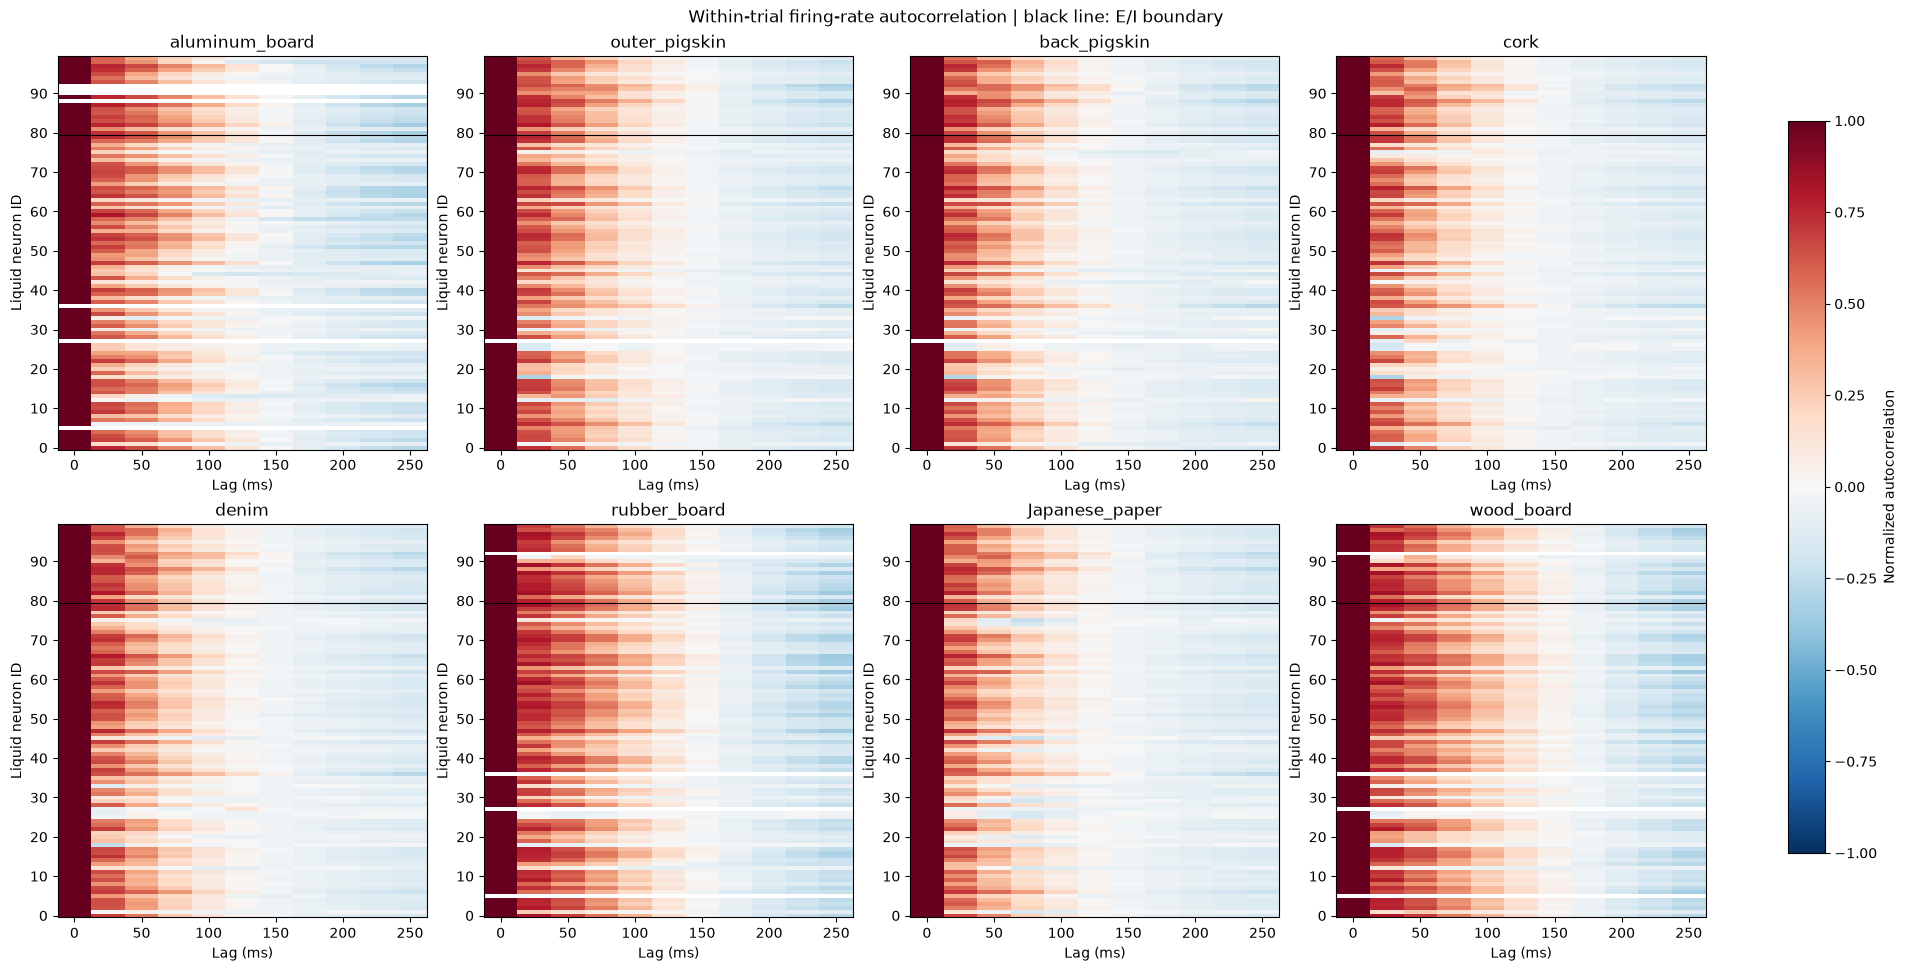

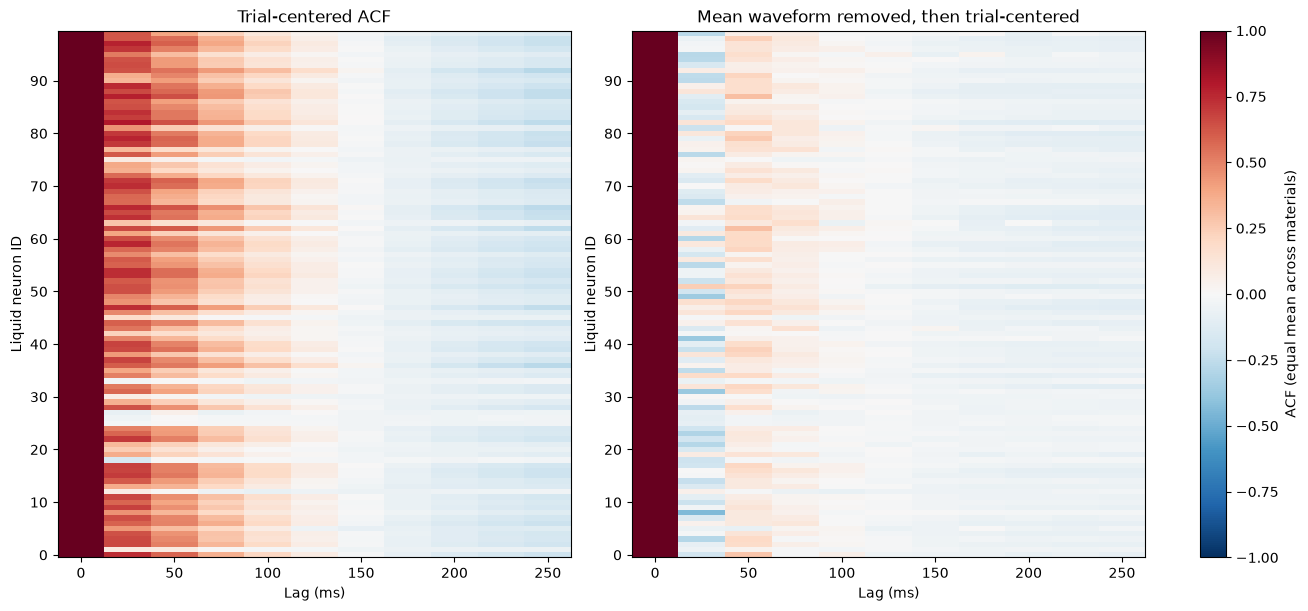

In [3]:
# 素材別：縦軸はニューロン、横軸は時間差。全図の色スケールを共通にする。
n_cols = 4
n_rows = (len(MATERIALS) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(19, 4.8*n_rows),
                          squeeze=False, layout='constrained')
for ax, material in zip(axes.flat, MATERIALS):
    im = ax.imshow(np.ma.masked_invalid(acf_by_material[material]),
                   aspect='auto', origin='lower', cmap='RdBu_r', vmin=-1, vmax=1,
                   extent=[LAGS_MS[0]-BIN_MS/2, LAGS_MS[-1]+BIN_MS/2,
                           -0.5, len(NEURON_IDS)-0.5])
    ticks = np.arange(0, len(NEURON_IDS), 10)
    ax.set_yticks(ticks, NEURON_IDS[ticks])
    ax.set(xlabel='Lag (ms)', ylabel='Liquid neuron ID', title=material)
    if NEURON_SELECTION == 'all' and np.any(NEURON_TYPES == 'I'):
        ax.axhline(np.flatnonzero(NEURON_TYPES == 'I')[0]-.5, color='black', linewidth=.8)
for ax in axes.flat[len(MATERIALS):]: ax.set_visible(False)
fig.colorbar(im, ax=list(axes.flat), label='Normalized autocorrelation', shrink=.85)
fig.suptitle('Within-trial firing-rate autocorrelation | black line: E/I boundary')
plt.show()

# 素材平均の比較：平均応答波形を含む場合と、引いた場合。
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
for ax, values, title in zip(axes, [mean_acf, mean_residual_acf],
                             ['Trial-centered ACF', 'Mean waveform removed, then trial-centered']):
    im = ax.imshow(np.ma.masked_invalid(values), aspect='auto', origin='lower',
                   cmap='RdBu_r', vmin=-1, vmax=1,
                   extent=[LAGS_MS[0]-BIN_MS/2, LAGS_MS[-1]+BIN_MS/2,
                           -0.5, len(NEURON_IDS)-0.5])
    ticks = np.arange(0, len(NEURON_IDS), 10)
    ax.set_yticks(ticks, NEURON_IDS[ticks])
    ax.set(xlabel='Lag (ms)', ylabel='Liquid neuron ID', title=title)
fig.colorbar(im, ax=axes, label='ACF (equal mean across materials)')
plt.show()

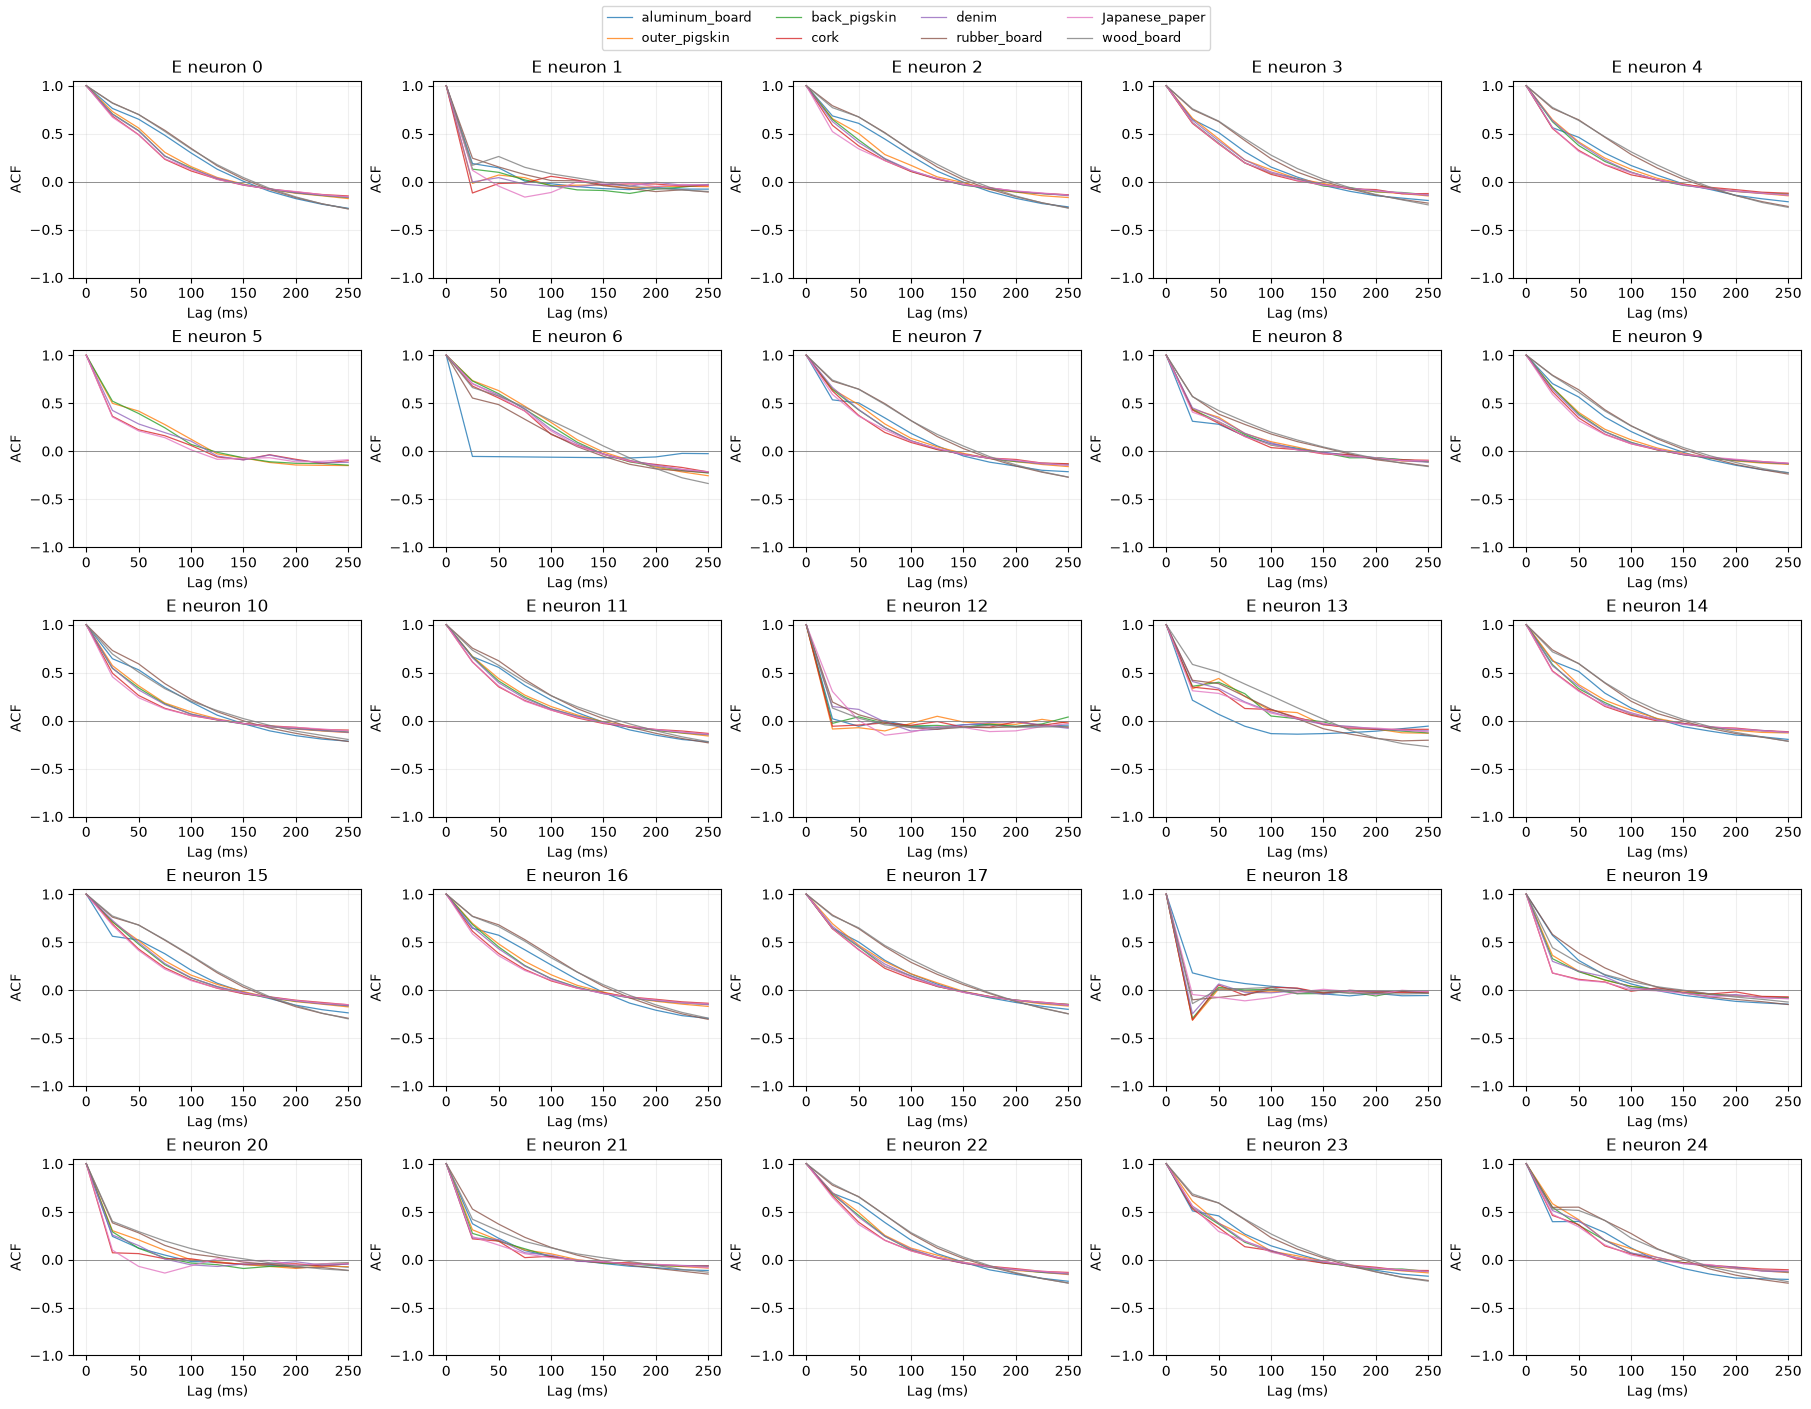

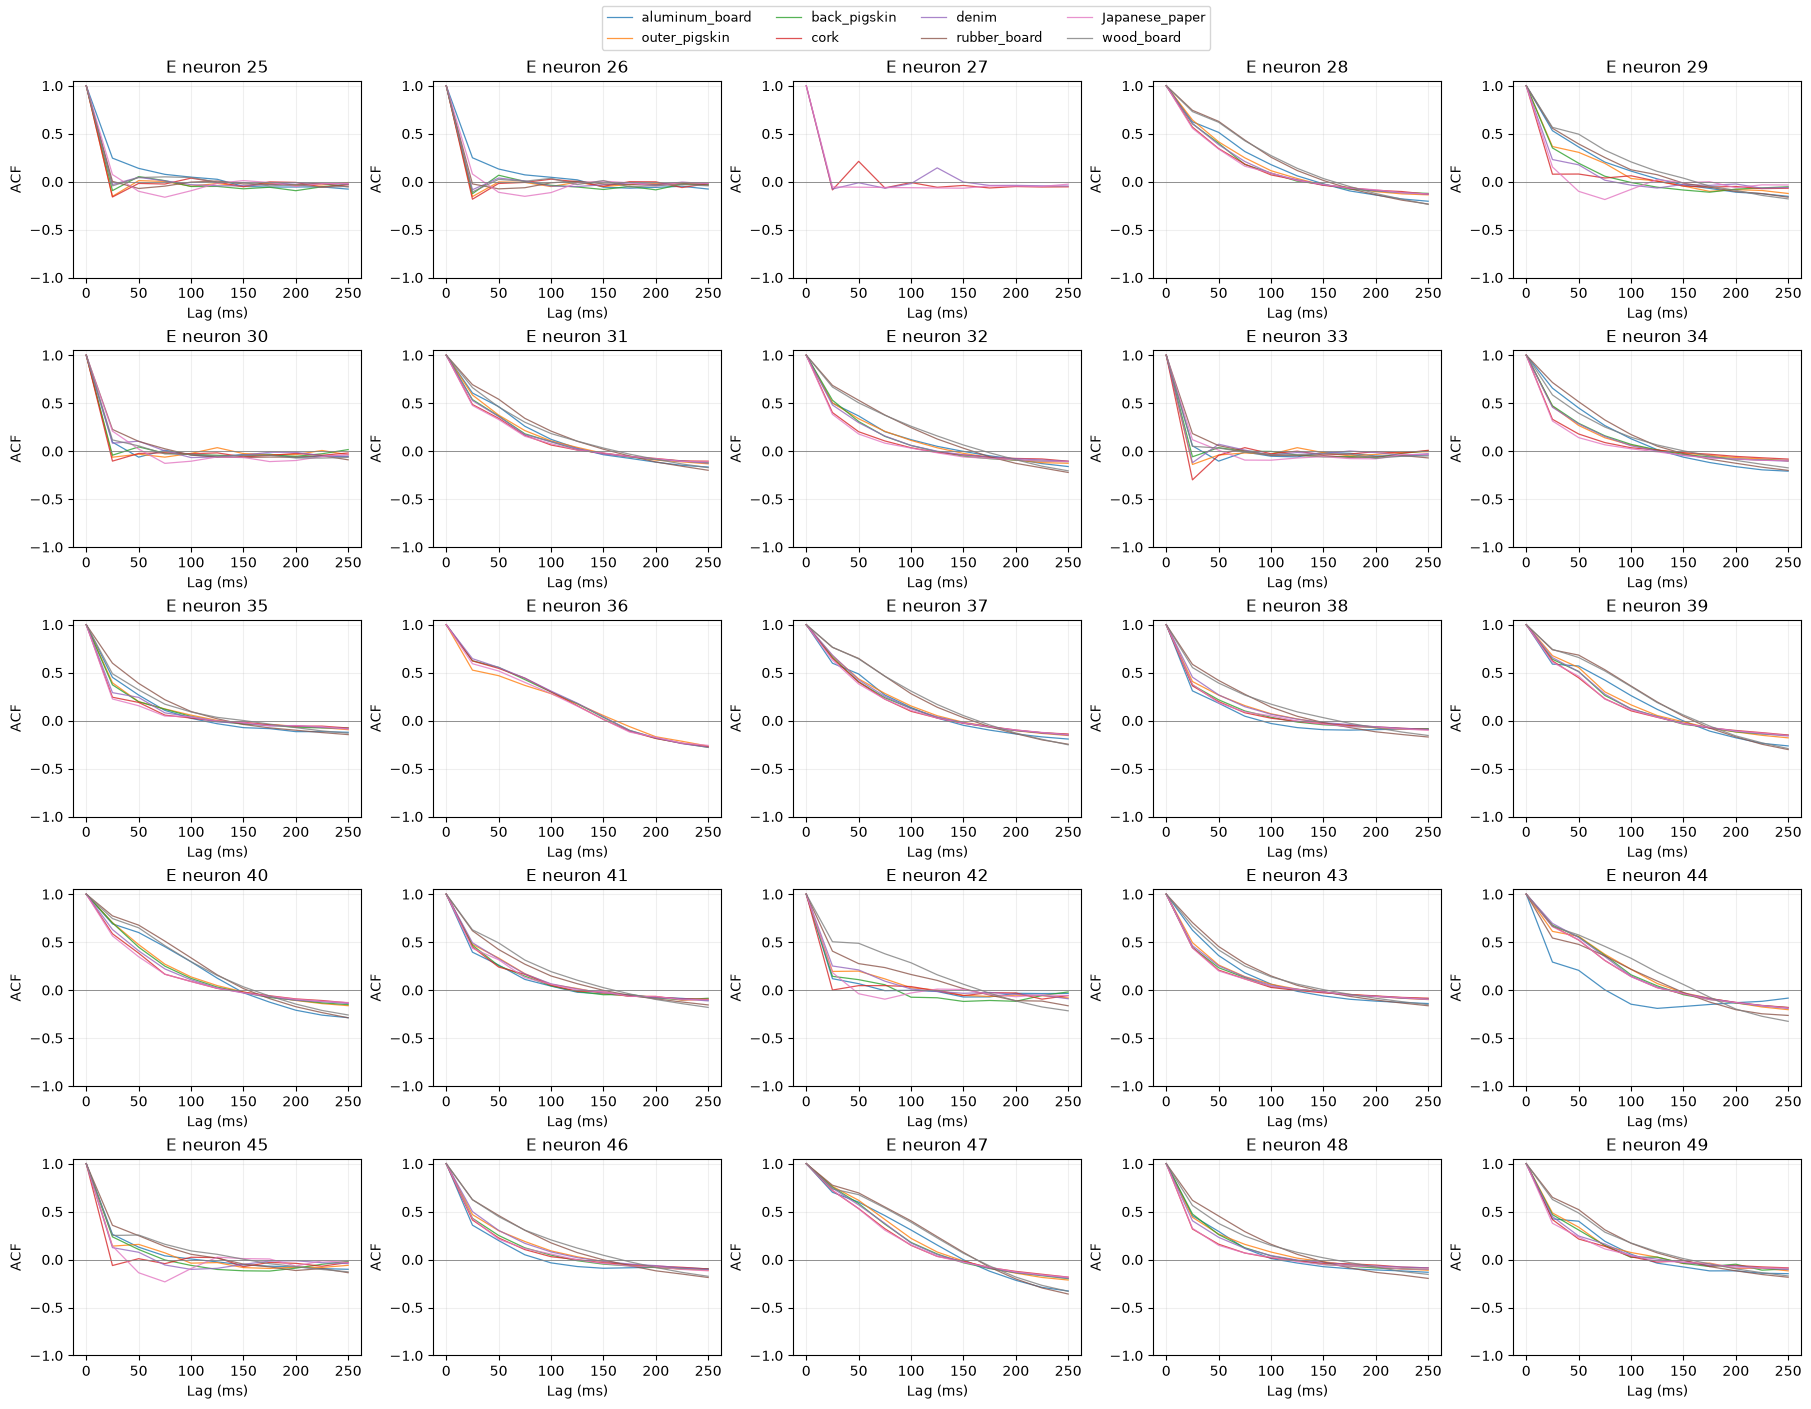

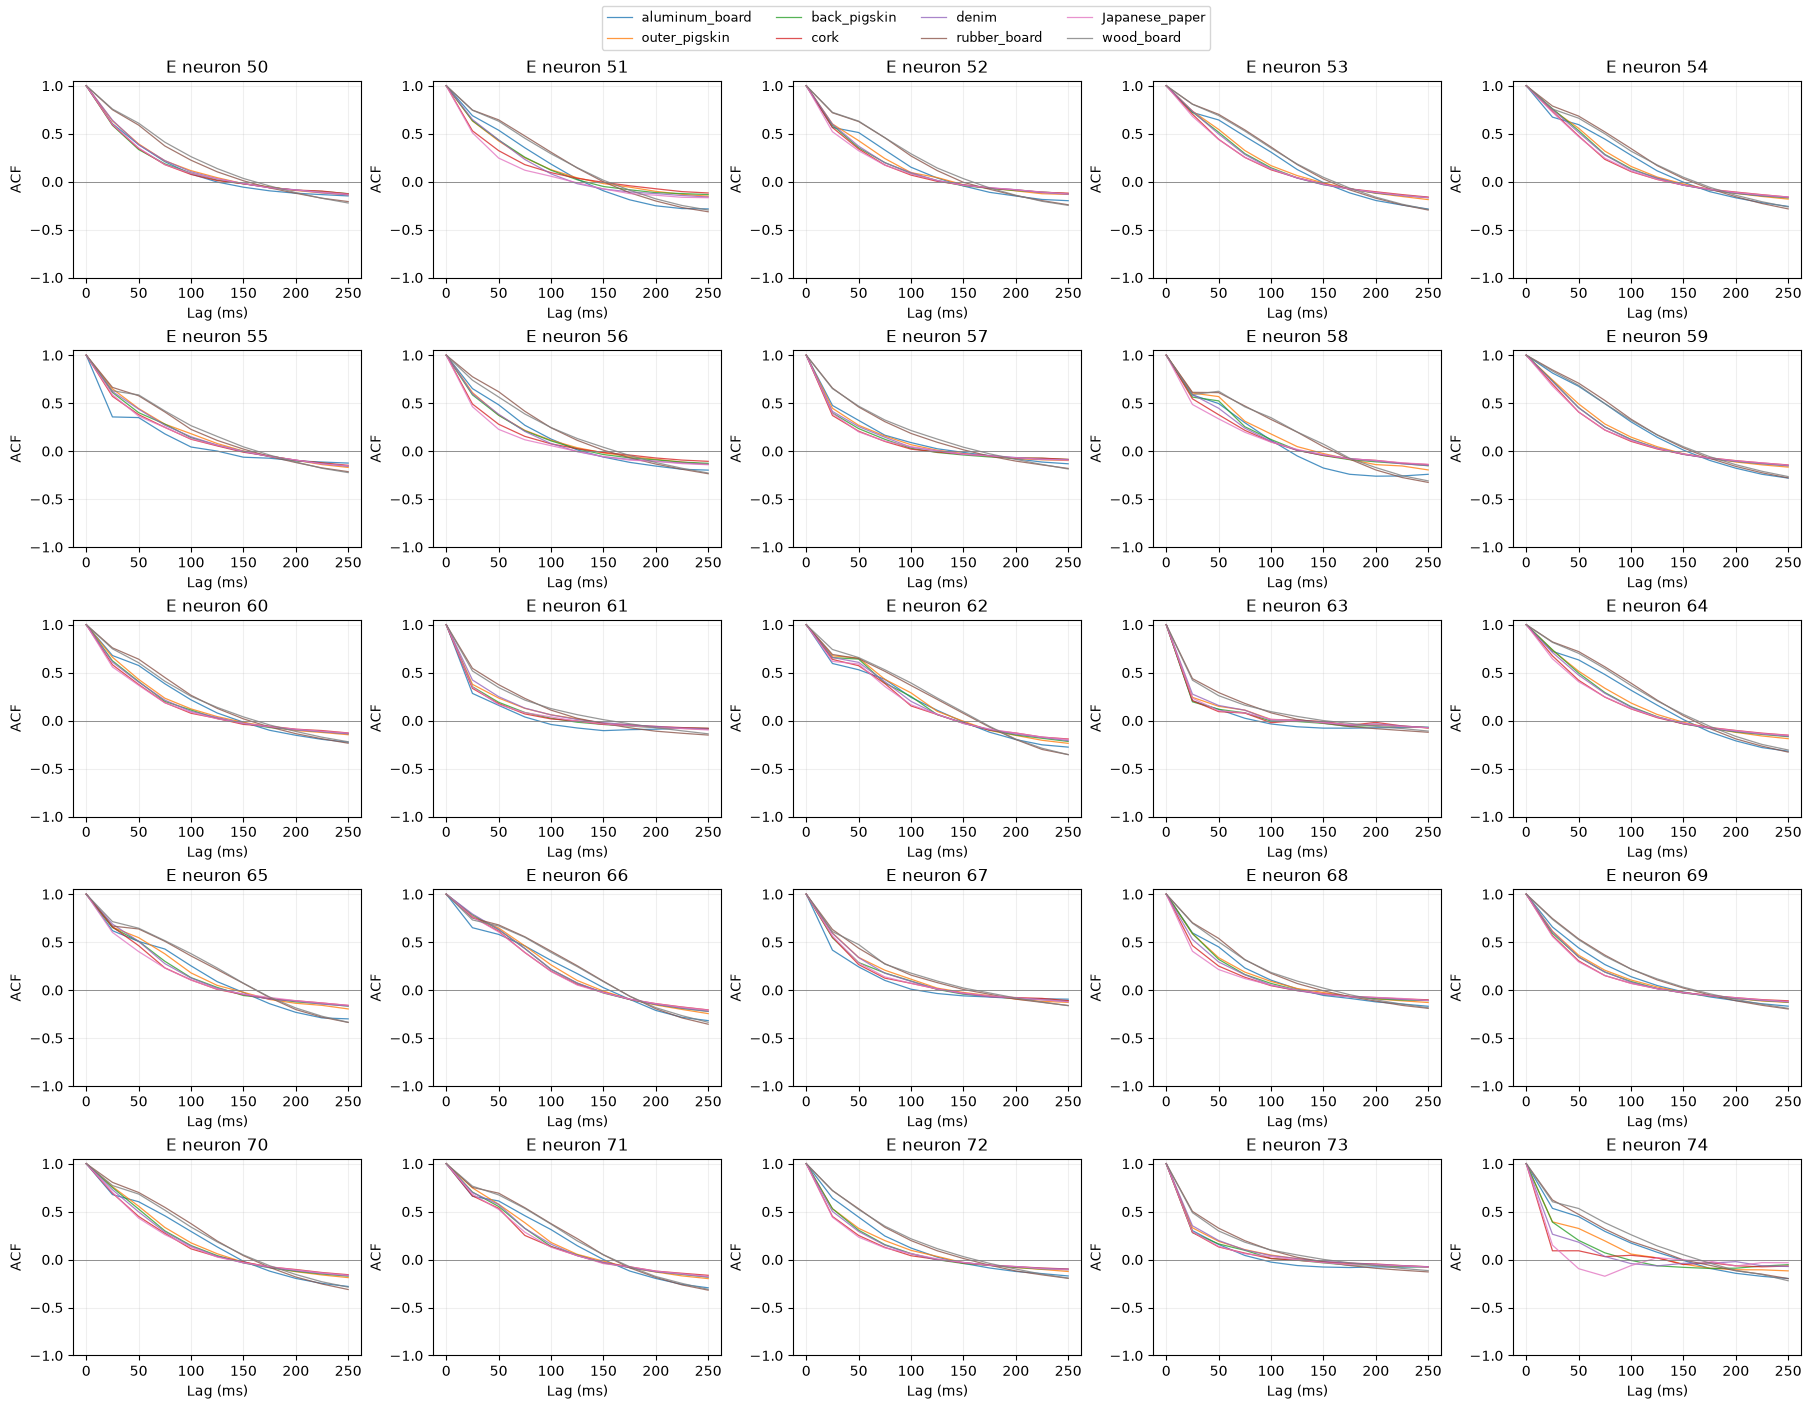

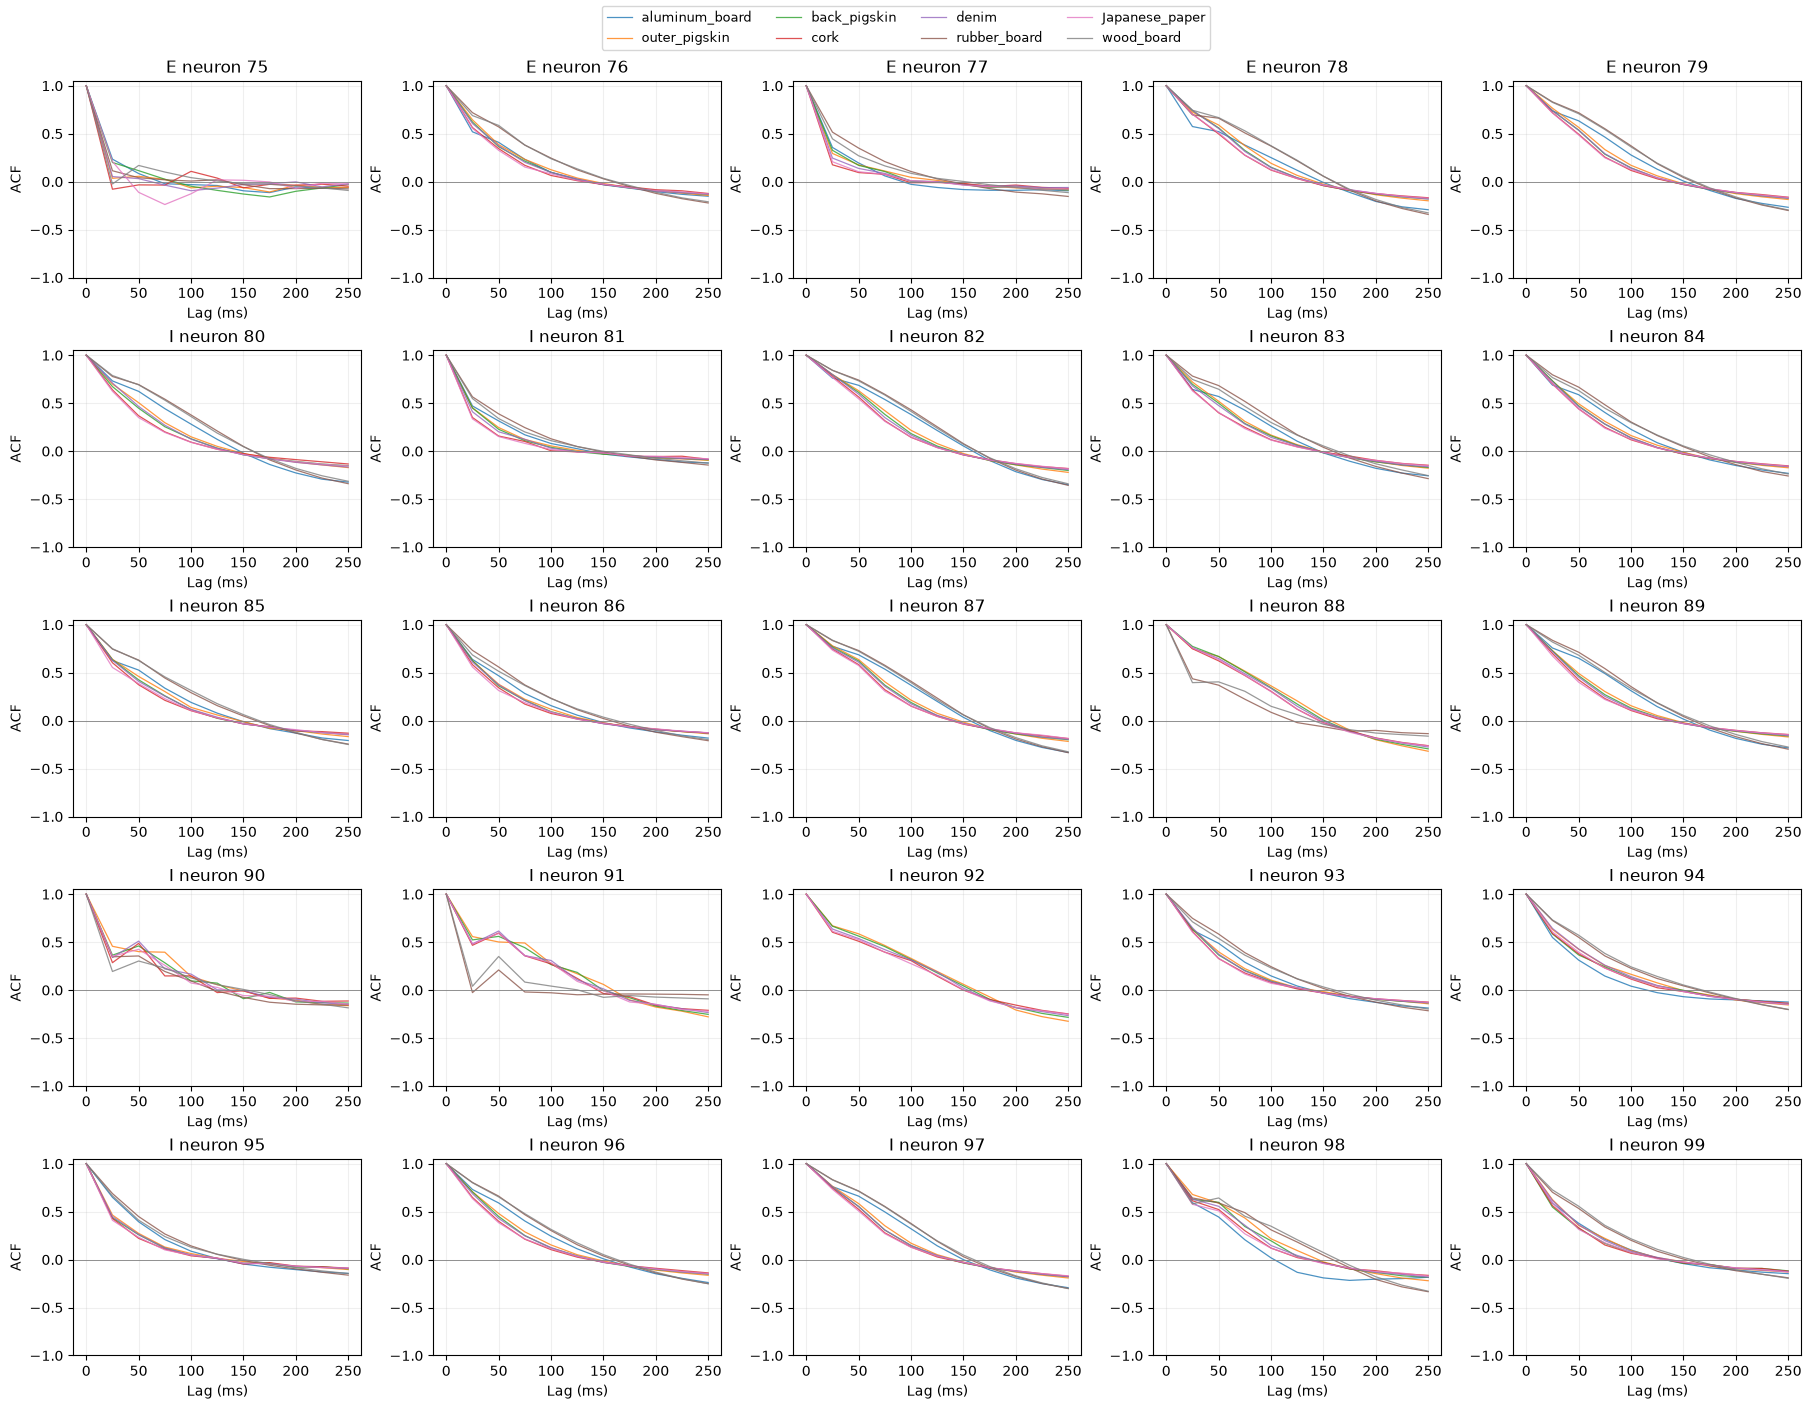

In [4]:
# 各ニューロンのACF曲線。25個ずつ表示し、素材ごとの違いを比較する。
NEURONS_PER_PAGE = 25
material_colors = [plt.get_cmap('tab10')(i % 10) for i in range(len(MATERIALS))]
for start in range(0, len(NEURON_IDS), NEURONS_PER_PAGE):
    positions = np.arange(start, min(start+NEURONS_PER_PAGE, len(NEURON_IDS)))
    columns = 5
    rows = (len(positions)+columns-1)//columns
    fig, axes = plt.subplots(rows, columns, figsize=(18, 2.8*rows),
                             squeeze=False, layout='constrained')
    for ax, j in zip(axes.flat, positions):
        for material, color in zip(MATERIALS, material_colors):
            ax.plot(LAGS_MS, acf_by_material[material][j], color=color,
                    linewidth=.9, alpha=.8, label=material)
        ax.axhline(0, color='gray', linewidth=.6)
        ax.set(title=f'{NEURON_TYPES[j]} neuron {NEURON_IDS[j]}',
               xlabel='Lag (ms)', ylabel='ACF', ylim=(-1, 1.05))
        ax.grid(alpha=.2)
    for ax in axes.flat[len(positions):]: ax.set_visible(False)
    handles, legends = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, legends, loc='outside upper center', ncol=4, fontsize=9)
    plt.show()

## 読み取り上の注意

- 25 msの自己相関が高いニューロンは、隣り合うビンの変動が似ている。長いlagまで正の値が続く場合は、ゆっくりした時間変化がある可能性がある。
- 正負が交互に現れる場合は、波形の増減や周期性が候補になる。ただし、20ビンという短さと時間平均の除去自体が負の相関を生むため、周期と断定しない。
- 平均波形を引くと相関が大きく減る場合、素材に同期した共通波形が主に寄与していた可能性がある。
- 自己相関だけで、再帰結合の効果や素材分類への貢献は判断できない。今回の量は**ビン発火率の自己相関**であり、スパイク間隔やサブ25 msのスパイク自己相関ではない。
- 保存された校正データは試行ごとに状態を初期化しているため、試行をまたぐ記憶はこの解析の対象に含まれない。